In [ ]:
import pandas as pd
df=pd.read_csv("../data/cleaned_reviews.csv")

print("Shape of the dataset:", df.shape)


Shape of the dataset: (393579, 2)


In [5]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

X = df["Text"]
y = df["Sentiment"]

X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.25, random_state=42, stratify=y_temp
)

tfidf = TfidfVectorizer(max_features=20000, stop_words="english")

X_train_tfidf = tfidf.fit_transform(X_train)
X_val_tfidf = tfidf.transform(X_val)
X_test_tfidf = tfidf.transform(X_test)

In [22]:
print(X_val.shape)
print(y_val.head(78716).value_counts())



(78716,)
Sentiment
Positive    61352
Negative    11413
Neutral      5951
Name: count, dtype: int64


In [ ]:
from sklearn.linear_model import LogisticRegression
model=LogisticRegression(max_iter=1000)
model.fit(X_train_tfidf,y_train)
print("Training complete") 


,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [ ]:
y_pred=model.predict(X_val_tfidf)
print("Predictions complete")
print(y_pred[:10])

results=pd.DataFrame({"Review": X_val, "Actual": y_val, "Predicted": y_pred})
print(results.head(10))

Predictions complete
['Positive' 'Positive' 'Positive' 'Positive' 'Positive' 'Positive'
 'Positive' 'Positive' 'Positive' 'Positive']
                                                   Review    Actual Predicted
209033  These are extremely easy to make and it takes ...  Positive  Positive
8556    I am impressed with Mr Puck's different blends...  Positive  Positive
36142   Gotta love Tootsie Pops!!!! But the ones I lov...  Positive  Positive
155694  Very good Honey for the Money, nice taste of M...  Positive  Positive
106446  This is a good morning coffee, it's nice and s...  Positive  Positive
56200   I've tried several brands of falafel mix, and ...  Positive  Positive
48902   We have used this product for years and drink ...  Positive  Positive
296993  This is one of my fav chilled drinks, and this...  Positive  Positive
158572  I have purchased Talking Rain from Costco for ...  Positive  Positive
37361   Spice lovers, this is the real deal.  I've had...  Positive  Positive


In [26]:
print("Actual validation labels:")
print(y_val.value_counts())

print("\nActual percentages:")
print(pd.Series(y_val).value_counts(normalize=True) * 100)

print("\nPredicted validation labels:")
print(pd.Series(y_pred).value_counts())

print("\nPrediction percentages:")
print(pd.Series(y_pred).value_counts(normalize=True) * 100)

Actual validation labels:
Sentiment
Positive    61352
Negative    11413
Neutral      5951
Name: count, dtype: int64

Actual percentages:
Sentiment
Positive    77.940952
Negative    14.498958
Neutral      7.560089
Name: proportion, dtype: float64

Predicted validation labels:
Positive    66775
Negative    10127
Neutral      1814
Name: count, dtype: int64

Prediction percentages:
Positive    84.830276
Negative    12.865237
Neutral      2.304487
Name: proportion, dtype: float64


In [28]:
from sklearn.metrics import classification_report
print("\nClassification Report:")
print(classification_report(y_val,y_pred))


Classification Report:
              precision    recall  f1-score   support

    Negative       0.73      0.65      0.69     11413
     Neutral       0.48      0.15      0.22      5951
    Positive       0.89      0.97      0.93     61352

    accuracy                           0.86     78716
   macro avg       0.70      0.59      0.61     78716
weighted avg       0.84      0.86      0.84     78716



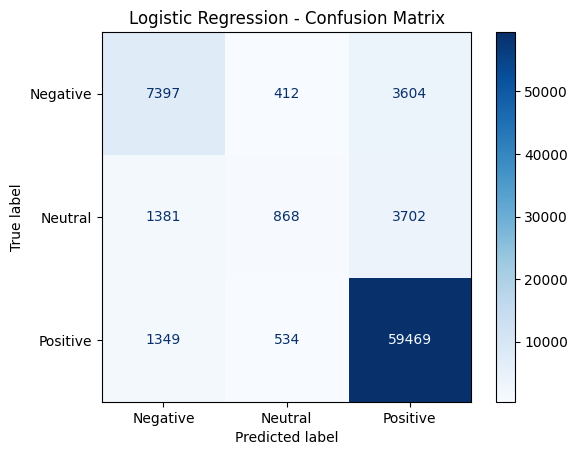

In [29]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_val, y_pred, labels=["Negative", "Neutral", "Positive"])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Neutral", "Positive"]
)

disp.plot(cmap="Blues")
plt.title("Logistic Regression - Confusion Matrix")
plt.show()